In [200]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Exploration et analyse des données (EDA)

In [201]:
df = sns.load_dataset("iris")

In [202]:
df.shape

(150, 5)

In [203]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [204]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [205]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


### 1.2 Types de variables, valeurs manquantes et doublons

In [206]:
df.dtypes

sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

In [207]:
df.isna().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [208]:
df.duplicated().sum()

np.int64(1)

In [209]:
df[(df["petal_length"]<0 )| (df["petal_width"]<0) | (df["sepal_length"]<0)|(df["sepal_width"]<0)].sum()

sepal_length    0.0
sepal_width     0.0
petal_length    0.0
petal_width     0.0
species            
dtype: object

<Axes: xlabel='species', ylabel='count'>

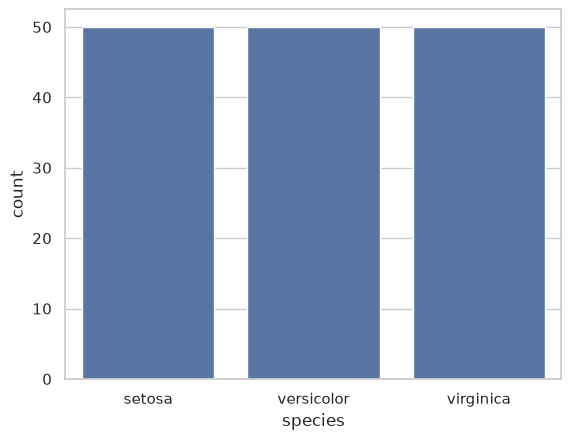

In [210]:
sns.countplot(df,x="species")

les classes sont bien equilibrés

<Axes: xlabel='petal_length'>

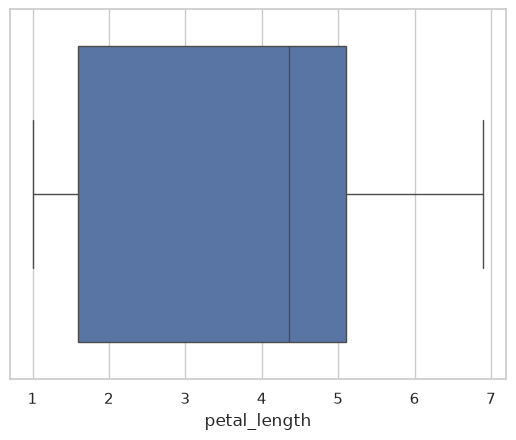

In [211]:
sns.boxplot(df,x="petal_length")

<Axes: xlabel='species', ylabel='petal_length'>

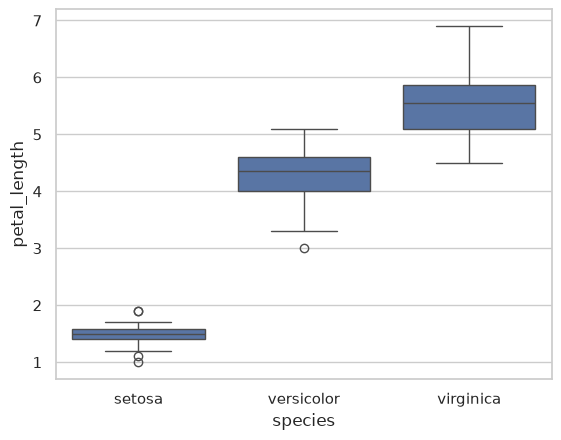

In [212]:
sns.boxplot(df,x="species",y="petal_length")

<Axes: >

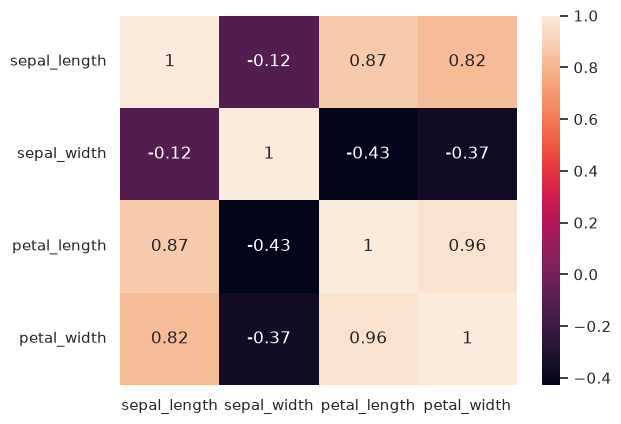

In [213]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [214]:
df = df.drop_duplicates()

In [215]:
X=df.drop(columns=["species"])
y=df["species"]
numeric_features= ["sepal_length","sepal_width","petal_length","petal_width"]

In [216]:
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size=0.2,random_state=42)

In [217]:
preprocessor = ColumnTransformer([
    ("standarization",StandardScaler(),numeric_features)
])

In [218]:
model = Pipeline([
    ("preprocessor",preprocessor),
    ("model",KNeighborsClassifier())
])

## 7. Entraînement


In [219]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['setosa','versicolor','virginica']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal_length','sepal_width','petal_length','petal_width']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('standarization', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passth

In [220]:
cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
cross_val_score(estimator=model,X=X_train,y=y_train,cv=cv)

array([0.95      , 0.9       , 0.97435897])

In [221]:
params = {
    "model__n_neighbors":[3,5,7,9],
    "model__leaf_size":[30,50,70,90]
}
grid_search = GridSearchCV(
    estimator=model,
    param_grid=params,
    cv=5
)
grid_search.fit(X_train,y_train)
print("params: ",grid_search.best_params_)
print("scores: ",grid_search.best_score_)
print("estimator: ",grid_search.best_estimator_)

params:  {'model__leaf_size': 30, 'model__n_neighbors': 3}
scores:  0.9496376811594203
estimator:  Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('standarization',
                                                  StandardScaler(),
                                                  ['sepal_length',
                                                   'sepal_width',
                                                   'petal_length',
                                                   'petal_width'])])),
                ('model', KNeighborsClassifier(n_neighbors=3))])


In [222]:

y_pred = grid_search.best_estimator_.predict(X_test)
accuracy= accuracy_score(y_test,y_pred)
precision= precision_score(y_test,y_pred,average="macro")
f1= f1_score(y_test,y_pred,average="macro")
recall= recall_score(y_test,y_pred,average="macro")
print("recall",recall)
print("f1",f1)
print("accuracy",accuracy)
print("precision",precision)

recall 1.0
f1 1.0
accuracy 1.0
precision 1.0


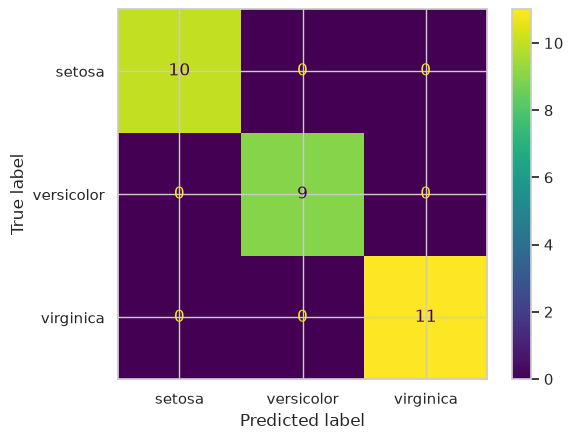

In [223]:
# sns.heatmap(confusion_matrix(y_test,y_pred),annot=True)
ConfusionMatrixDisplay.from_estimator(grid_search.best_estimator_,X_test,y_test)